# PAD-UFES-20 Skin Lesion Dataset: Image EDA

Exploratory analysis of the PAD-UFES-20 clinical image dataset ahead of CNN-based skin lesion classification.

**Our image EDA will focus on:**
- Number of images and their distribution across the three folders.
- Image dimensions and resolution.
- Sample image visualisation.
- Pixel intensity, brightness and contrast.
- Image quality and corrupted files.
- Duplicate images.

## 1. Setup


In [ ]:
#Install dependencies (only if needed)
# Uncomment and run ONCE if a package is missing, then restart the kernel.
# `%pip` installs into the environment this notebook's kernel is actually using
# (a plain `!pip` can target a different Python and leave the kernel unchanged).
# %pip install opencv-python numpy pandas matplotlib seaborn

## 2.Imports

In [3]:
import hashlib
import os
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Display settings
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("Python executable:", sys.executable)
print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("OpenCV version:", cv2.__version__)

print("All libraries imported successfully!")

Python executable: C:\Users\Kanakan\AppData\Local\Programs\Python\Python311\python.exe
Python version: 3.11.5 (tags/v3.11.5:cce6ba9, Aug 24 2023, 14:38:34) [MSC v.1936 64 bit (AMD64)]
NumPy version: 2.4.6
OpenCV version: 4.11.0
All libraries imported successfully!


## 1.3 Configuration

In [5]:
# ---- Paths -----------------------------------------------------------
DEFAULT_DATASET_DIR = "PAD-UFES Dataset"   # relative to this notebook; edit if needed
DATASET_DIR = Path(os.environ.get("PAD_UFES_DIR", DEFAULT_DATASET_DIR)).expanduser().resolve()

# ---- Reproducibility -------------------------------------------------
SEED = 42

# ---- Metadata column names -------------------------------------------
ID_COL = "img_id"
LABEL_COL = "diagnostic"
PATIENT_COL = "patient_id"
LESION_COL = "lesion_id"

# ---- Validate paths --------------------------------------------------
if not DATASET_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Set the PAD_UFES_DIR environment variable or edit DEFAULT_DATASET_DIR."
    )

# Look for metadata.csv in the dataset root first, then anywhere beneath it
CSV_PATH = DATASET_DIR / "metadata.csv"
if not CSV_PATH.is_file():
    matches = sorted(DATASET_DIR.rglob("metadata.csv"))
    if not matches:
        raise FileNotFoundError(f"metadata.csv not found under {DATASET_DIR}")
    CSV_PATH = matches[0]

print("Dataset folder:", DATASET_DIR)
print("Metadata CSV  :", CSV_PATH)

Dataset folder: C:\Users\Kanakan\Skin Lesion Classification\PG-Group-3---Multimodal-Skin-Lesion-Classification-Skin-Cancer-Detection-\PAD-UFES Dataset
Metadata CSV  : C:\Users\Kanakan\Skin Lesion Classification\PG-Group-3---Multimodal-Skin-Lesion-Classification-Skin-Cancer-Detection-\PAD-UFES Dataset\metadata.csv


## 1.4 Helper functions


In [9]:
def to_gray_uint8(image: np.ndarray) -> np.ndarray:
    """Convert a decoded image (1, 2, 3 or 4 channels; 8 or 16 bit) to 8-bit grayscale."""
    if image.dtype != np.uint8:
        image = cv2.convertScaleAbs(image, alpha=255.0 / np.iinfo(image.dtype).max)
    if image.ndim == 2:
        return image
    channels = image.shape[2]
    if channels == 2:                       # grayscale + alpha
        return image[:, :, 0]
    if channels == 4:                       # BGRA
        return cv2.cvtColor(image, cv2.COLOR_BGRA2GRAY)
    return cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


def load_rgb(path):
    """Read an image as RGB for plotting. Returns None if the file cannot be decoded.

    Uses np.fromfile + imdecode instead of cv2.imread so that paths containing
    non-ASCII characters also work on Windows.
    """
    raw = np.fromfile(path, dtype=np.uint8)
    image = cv2.imdecode(raw, cv2.IMREAD_COLOR)
    return None if image is None else cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def show_image(ax, path, title="", fontsize=8):
    """Draw an image on a matplotlib axis, with a placeholder if it cannot be read."""
    image = load_rgb(path)
    if image is None:
        ax.text(0.5, 0.5, "unreadable", ha="center", va="center")
    else:
        ax.imshow(image)
    ax.set_title(title, fontsize=fontsize)
    ax.axis("off")

## 2. Image inventory and feature extraction

Each image is read from disk **once**, and all of the following are computed in the same pass:
dimensions, channel count, file size, MD5 hash (for duplicate detection), brightness, contrast and sharpness.

In [10]:
# Locate image files
# (imgs_part_1/imgs_part_1/*.png) or flat (imgs_part_1/*.png).
image_files = sorted(
    p for p in DATASET_DIR.rglob("*") if p.is_file() and p.suffix.lower() == ".png"
)

if not image_files:
    raise FileNotFoundError(f"No .png images found under {DATASET_DIR}")

print("Images per folder:")
print(pd.Series([p.parent.name for p in image_files]).value_counts().sort_index().to_string())
print("\nTotal PNG images:", len(image_files))

Images per folder:
imgs_part_1    911
imgs_part_2    659
imgs_part_3    728

Total PNG images: 2298


In [12]:
# Extract image properties, quality metrics and hashes
records = []
unreadable_files = []

for image_path in image_files:
    raw = np.fromfile(image_path, dtype=np.uint8)
    md5 = hashlib.md5(raw).hexdigest()

    # IMREAD_UNCHANGED keeps the true channel count 
    image = cv2.imdecode(raw, cv2.IMREAD_UNCHANGED)
    if image is None:
        unreadable_files.append(image_path.name)
        continue

    height, width = image.shape[:2]
    channels = 1 if image.ndim == 2 else image.shape[2]
    gray = to_gray_uint8(image)

    records.append({
        "filename": image_path.name,
        "folder": image_path.parent.name,
        "path": image_path,
        "width": width,
        "height": height,
        "channels": channels,
        "file_size_kb": image_path.stat().st_size / 1024,
        "md5": md5,
        "brightness": gray.mean(),                          # mean pixel intensity
        "contrast": gray.std(),                             # std of pixel intensity
        "sharpness": cv2.Laplacian(gray, cv2.CV_64F).var(), # variance of Laplacian
    })

image_df = pd.DataFrame(records)
image_df["aspect_ratio"] = image_df["width"] / image_df["height"]

if image_df.empty:
    raise RuntimeError("None of the image files could be decoded.")

print("Successfully read images:", len(image_df))
print("Unreadable images       :", len(unreadable_files))
if unreadable_files:
    print("  ->", unreadable_files)

# Filenames must be unique across folders: they are the join key to the metadata
n_repeated_names = image_df["filename"].duplicated().sum()
print("Filenames repeated across folders:", n_repeated_names)

display(image_df.drop(columns=["path", "md5"]).head())

Successfully read images: 2298
Unreadable images       : 0
Filenames repeated across folders: 0


,filename,folder,width,height,channels,file_size_kb,brightness,contrast,sharpness,aspect_ratio
0,PAT_100_393_595.png,imgs_part_1,394,394,4,202.843750,115.565069,16.713571,27.087613,1.000000
1,PAT_100_393_898.png,imgs_part_1,221,221,4,75.393555,168.416924,22.918493,30.521117,1.000000
2,PAT_101_1041_651.png,imgs_part_1,1131,1131,4,1765.536133,103.208205,14.912931,72.362719,1.000000
3,PAT_101_1041_658.png,imgs_part_1,741,740,4,822.568359,98.767812,17.364047,78.629533,1.001351
4,PAT_101_1041_898.png,imgs_part_1,1795,1796,4,4882.708984,136.969008,14.761016,23.418163,0.999443


## 3. Image dimensions and aspect ratio

In [13]:
# Image dimensions and aspect ratio

print("Image dimension statistics:")

display(
    image_df[["width", "height", "channels", "file_size_kb"]].describe()
)

Image dimension statistics:


,width,height,channels,file_size_kb
count,2298.000000,2298.000000,2298.000000,2298.000000
mean,933.679721,933.605309,3.626632,1532.639485
std,534.598513,534.668475,0.483804,1717.018689
min,147.000000,147.000000,3.000000,36.581055
25%,528.000000,527.250000,3.000000,435.087646
50%,779.500000,779.500000,4.000000,934.603516
75%,1219.250000,1218.750000,4.000000,2004.163574
max,3474.000000,3476.000000,4.000000,23064.569336


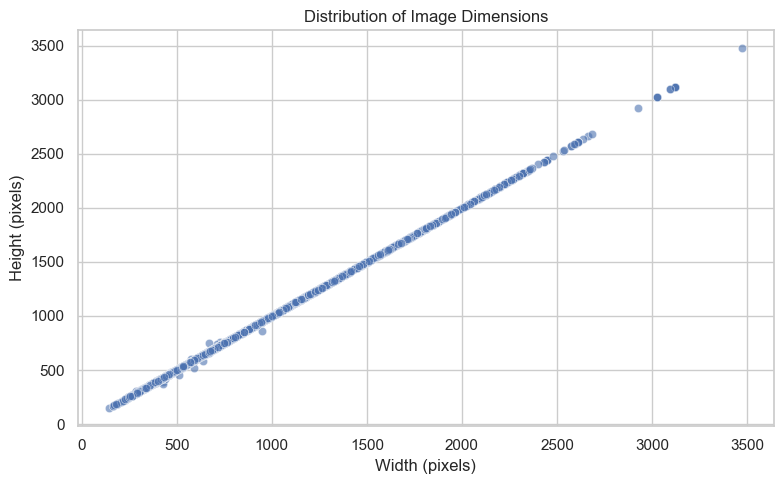

In [14]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=image_df, x="width", y="height", alpha=0.6)
plt.title("Distribution of Image Dimensions")
plt.xlabel("Width (pixels)")
plt.ylabel("Height (pixels)")
plt.tight_layout()
plt.show()

The dataset contains images with considerable variation in spatial resolution, which makes image resizing an important preprocessing requirement before CNN training.

count    2298.000000
mean        1.000189
std         0.007153
min         0.888446
25%         1.000000
50%         1.000000
75%         1.000000
max         1.156757
Name: aspect_ratio, dtype: float64

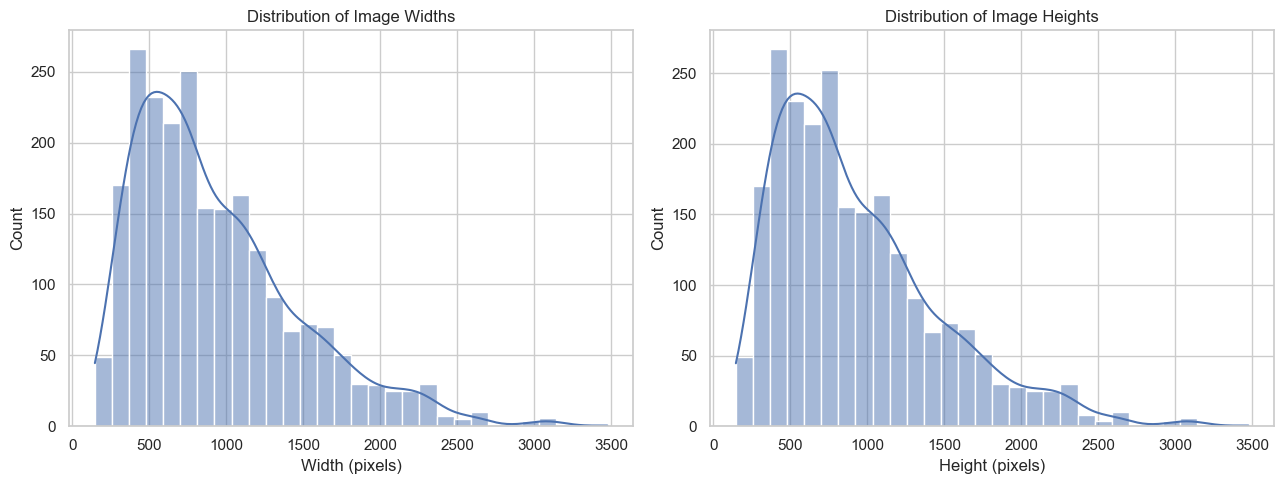

In [15]:
display(image_df["aspect_ratio"].describe())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(image_df["width"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Image Widths")
axes[0].set_xlabel("Width (pixels)")

sns.histplot(image_df["height"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Image Heights")
axes[1].set_xlabel("Height (pixels)")

plt.tight_layout()
plt.show()

**Implication for CNN preprocessing:** images can be resized to a common resolution while preserving their aspect ratios. Since most images are already square, this should be relatively straightforward.

## 4. Random sample of images

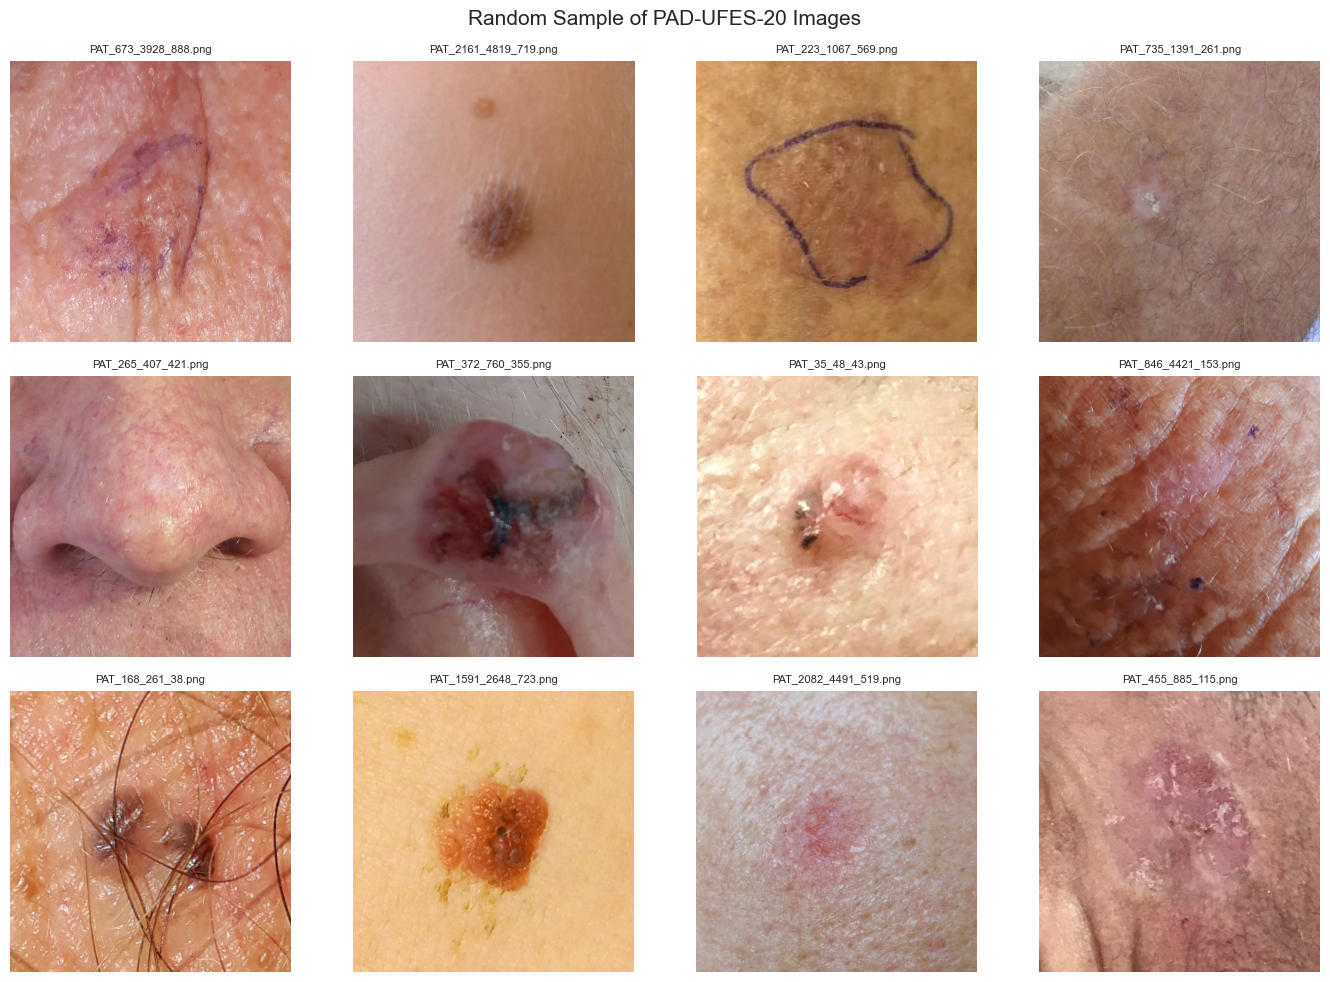

In [16]:
sample_df = image_df.sample(n=min(12, len(image_df)), random_state=SEED)

fig, axes = plt.subplots(3, 4, figsize=(14, 10))
axes = axes.flatten()

for ax, (_, row) in zip(axes, sample_df.iterrows()):
    show_image(ax, row["path"], row["filename"])

for ax in axes[len(sample_df):]:   # hide unused panels if fewer than 12 images
    ax.axis("off")

plt.suptitle("Random Sample of PAD-UFES-20 Images", fontsize=15)
plt.tight_layout()
plt.show()

## 5. Brightness and Contrast

- **Brightness** = mean grayscale pixel intensity.
- **Contrast** = standard deviation of grayscale pixel intensity.

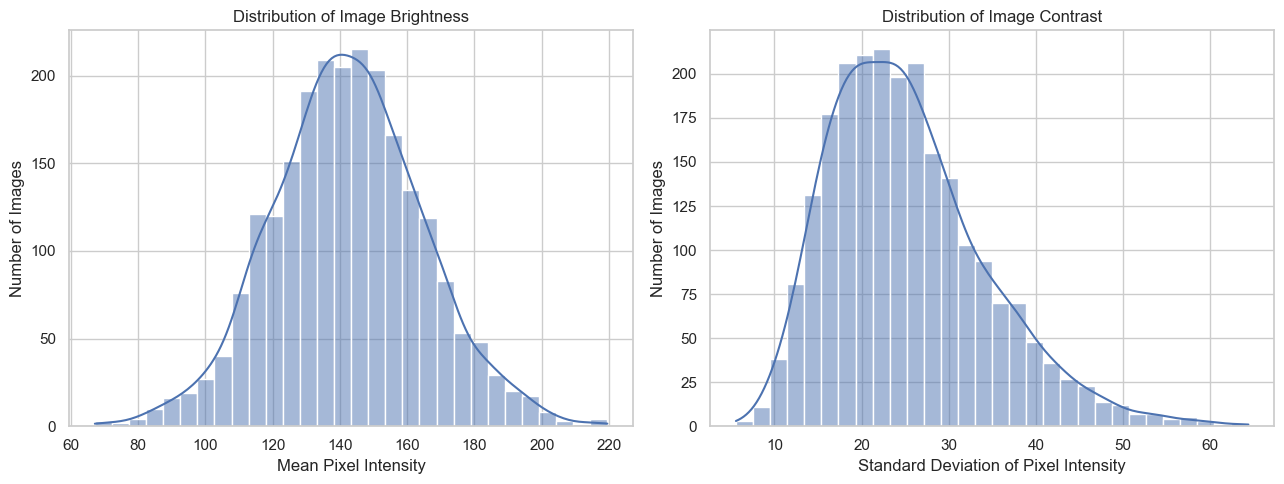

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(image_df["brightness"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Image Brightness")
axes[0].set_xlabel("Mean Pixel Intensity")
axes[0].set_ylabel("Number of Images")

sns.histplot(image_df["contrast"], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Image Contrast")
axes[1].set_xlabel("Standard Deviation of Pixel Intensity")
axes[1].set_ylabel("Number of Images")

plt.tight_layout()
plt.show()

In [18]:
display(image_df[["brightness", "contrast"]].describe())

,brightness,contrast
count,2298.000000,2298.000000
mean,142.378754,25.273900
std,22.345737,9.040785
min,67.214551,5.582341
25%,127.705446,18.680182
50%,142.187602,23.989255
75%,156.981746,30.281051
max,219.467968,64.367573


## 6. Sharpness

Sharpness is measured as the **variance of the Laplacian** of the grayscale image. Lower values indicate blurrier images.

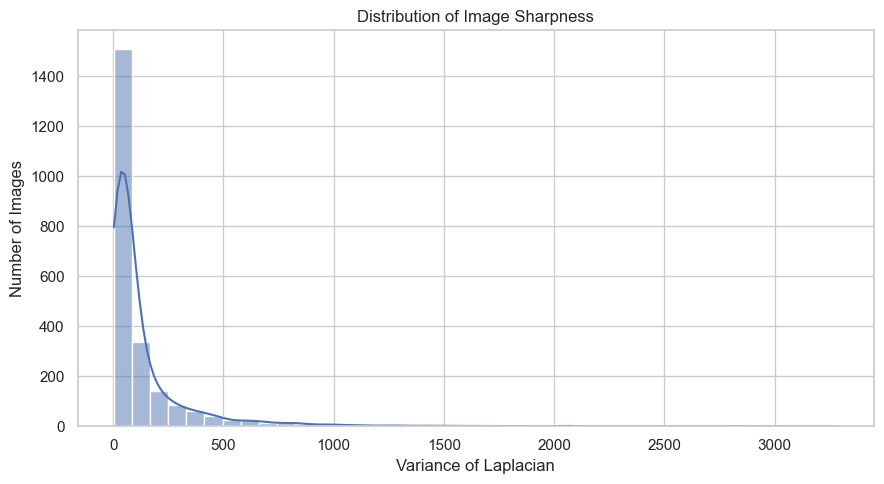

In [19]:
plt.figure(figsize=(9, 5))
sns.histplot(image_df["sharpness"], bins=40, kde=True)
plt.title("Distribution of Image Sharpness")
plt.xlabel("Variance of Laplacian")
plt.ylabel("Number of Images")
plt.tight_layout()
plt.show()

In [20]:
display(image_df["sharpness"].describe())

count    2298.000000
mean      129.923762
std       223.025391
min         3.475896
25%        27.378942
50%        52.725833
75%       126.166078
max      3286.341089
Name: sharpness, dtype: float64

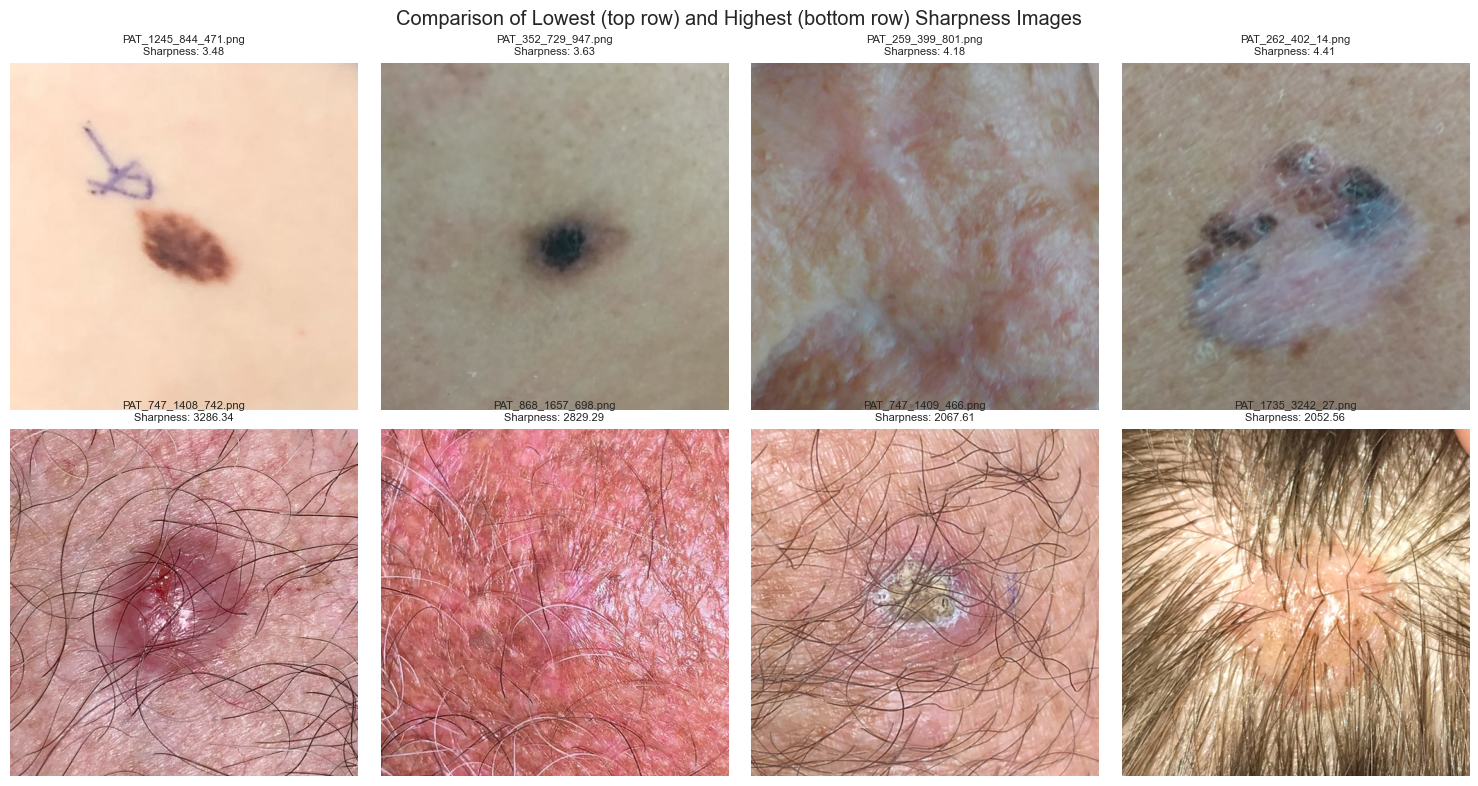

In [21]:
# Compare the 4 blurriest and the 4 sharpest images
n_extreme = min(4, len(image_df))
selected_df = pd.concat([
    image_df.nsmallest(n_extreme, "sharpness"),
    image_df.nlargest(n_extreme, "sharpness"),
])

fig, axes = plt.subplots(2, n_extreme, figsize=(3.75 * n_extreme, 8), squeeze=False)

for ax, (_, row) in zip(axes.flatten(), selected_df.iterrows()):
    show_image(ax, row["path"], f"{row['filename']}\nSharpness: {row['sharpness']:.2f}")

plt.suptitle("Comparison of Lowest (top row) and Highest (bottom row) Sharpness Images")
plt.tight_layout()
plt.show()

## 7. Duplicate image detection

Exact duplicates are found by comparing the MD5 hash of each file's bytes (computed in Section 2).
Visually similar but non-identical images are not detected by this method.

In [22]:
# {md5: [filenames]}, keeping only hashes shared by 2+ files.
# Groups are ordered by their first filename so group numbers are stable between runs.
duplicate_groups = {
    md5: sorted(group["filename"])
    for md5, group in image_df.groupby("md5")
    if len(group) > 1
}
duplicate_groups = dict(sorted(duplicate_groups.items(), key=lambda item: item[1][0]))

n_unique_files = image_df["md5"].nunique()

print("Total images checked          :", len(image_df))
print("Unique image files            :", n_unique_files)
print("Duplicate groups              :", len(duplicate_groups))
print("Number of extra duplicate copies:", len(image_df) - n_unique_files)

Total images checked          : 2298
Unique image files            : 2283
Duplicate groups              : 15
Number of extra duplicate copies: 15


In [23]:
for group_number, filenames in enumerate(duplicate_groups.values(), start=1):
    print(f"\nDuplicate group {group_number}:")
    for filename in filenames:
        print("  ", filename)


Duplicate group 1:
   PAT_202_307_424.png
   PAT_202_308_721.png

Duplicate group 2:
   PAT_302_650_477.png
   PAT_302_651_529.png

Duplicate group 3:
   PAT_311_666_191.png
   PAT_311_667_416.png

Duplicate group 4:
   PAT_38_1002_34.png
   PAT_38_1003_68.png

Duplicate group 5:
   PAT_38_1002_668.png
   PAT_38_1003_226.png

Duplicate group 6:
   PAT_419_2767_323.png
   PAT_419_833_148.png

Duplicate group 7:
   PAT_528_3072_615.png
   PAT_528_993_589.png

Duplicate group 8:
   PAT_56_86_479.png
   PAT_56_88_274.png

Duplicate group 9:
   PAT_570_1084_637.png
   PAT_570_1085_344.png

Duplicate group 10:
   PAT_570_1084_939.png
   PAT_570_1085_429.png

Duplicate group 11:
   PAT_691_1311_2.png
   PAT_691_3994_671.png

Duplicate group 12:
   PAT_691_1311_890.png
   PAT_691_3994_791.png

Duplicate group 13:
   PAT_701_1321_156.png
   PAT_701_4056_457.png

Duplicate group 14:
   PAT_759_1433_914.png
   PAT_759_1538_566.png

Duplicate group 15:
   PAT_834_1572_430.png
   PAT_834_1574_276.

## 8. Metadata and class distribution

In [24]:
metadata_df = pd.read_csv(CSV_PATH)

required_cols = {ID_COL, LABEL_COL, PATIENT_COL, LESION_COL}
missing_cols = required_cols - set(metadata_df.columns)
if missing_cols:
    raise KeyError(f"metadata.csv is missing expected columns: {sorted(missing_cols)}")

print("CSV shape:", metadata_df.shape)
print("\nColumn names:")
print(metadata_df.columns.tolist())

display(metadata_df.head())

CSV shape: (2298, 26)

Column names:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,cancer_history,has_piped_water,has_sewage_system,fitspatrick,region,diameter_1,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN,ARM,NaN,NaN,NEV,FALSE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,True,True,True,3.0,NECK,6.0,5.0,BCC,TRUE,TRUE,FALSE,TRUE,TRUE,TRUE,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,NaN,NaN,NaN,NaN,FACE,NaN,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,NaN,NaN,NaN,NaN,HAND,NaN,NaN,ACK,TRUE,FALSE,FALSE,FALSE,FALSE,FALSE,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,False,False,False,1.0,FOREARM,5.0,5.0,BCC,TRUE,TRUE,FALSE,FALSE,TRUE,TRUE,PAT_684_1302_588.png,True


In [25]:
# Count and percentage of images in each diagnosis class
class_counts = metadata_df[LABEL_COL].value_counts()
class_percentages = metadata_df[LABEL_COL].value_counts(normalize=True).mul(100)

class_distribution = pd.DataFrame({
    "image_count": class_counts,
    "percentage": class_percentages.round(2),
})
display(class_distribution)

# Class order used for all per-class plots (most to least frequent) - derived from the data
diagnosis_classes = class_counts.index.tolist()

print("Number of diagnosis classes:", metadata_df[LABEL_COL].nunique())
print("Missing diagnosis labels   :", metadata_df[LABEL_COL].isna().sum())
print("Missing image filenames    :", metadata_df[ID_COL].isna().sum())

,image_count,percentage
diagnostic,,
BCC,845,36.77
ACK,730,31.77
NEV,244,10.62
SEK,235,10.23
SCC,192,8.36
MEL,52,2.26


Number of diagnosis classes: 6
Missing diagnosis labels   : 0
Missing image filenames    : 0


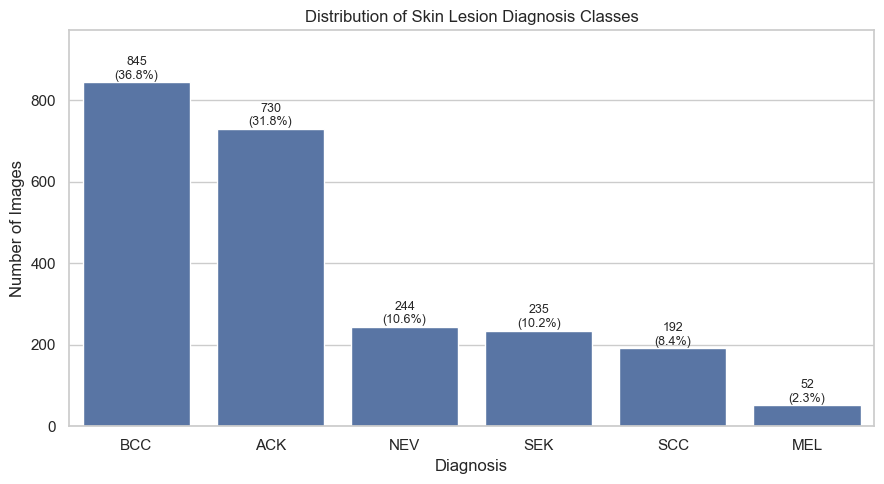

In [26]:
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=class_counts.index, y=class_counts.values)

plt.title("Distribution of Skin Lesion Diagnosis Classes")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Images")

# Count and percentage above each bar
offset = class_counts.max() * 0.01
for i, (count, pct) in enumerate(zip(class_counts.values, class_percentages.values)):
    ax.text(i, count + offset, f"{count}\n({pct:.1f}%)", ha="center", fontsize=9)

plt.ylim(0, class_counts.max() * 1.15)
plt.tight_layout()
plt.show()

The PAD-UFES-20 dataset contains six diagnosis classes, with no missing diagnosis labels. However, the class distribution is imbalanced. BCC (36.77%) and ACK (31.77%) are the most represented classes, while MEL accounts for only 2.26% of the images. This imbalance may affect the CNN's ability to learn minority classes effectively. Therefore, evaluation will include macro-F1, per-class precision and recall, and a confusion matrix in addition to accuracy. Class weighting will also be considered during model training.

## 9. Patients and lesions

In [27]:
print("Total image records:", len(metadata_df))
print("Unique patients    :", metadata_df[PATIENT_COL].nunique())
print("Unique lesions     :", metadata_df[LESION_COL].nunique())

print("\nImages per patient:")
print(metadata_df.groupby(PATIENT_COL)[ID_COL].count().describe())

print("\nImages per lesion:")
print(metadata_df.groupby(LESION_COL)[ID_COL].count().describe())

# Sanity check: lesion IDs should belong to exactly one patient
max_patients_per_lesion = metadata_df.groupby(LESION_COL)[PATIENT_COL].nunique().max()
print("\nMax patients sharing one lesion_id:", max_patients_per_lesion)

Total image records: 2298
Unique patients    : 1373
Unique lesions     : 1641

Images per patient:
count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: img_id, dtype: float64

Images per lesion:
count    1641.000000
mean        1.400366
std         0.686081
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: img_id, dtype: float64

Max patients sharing one lesion_id: 2


**Key observations**

*Patient level*
- There are 1,373 unique patients for 2,298 image records.
- Each patient has an average of approximately 1.67 images.
- Some patients have up to 10 images.

*Lesion level*
- There are 1,641 unique lesions.
- Each lesion has an average of approximately 1.4 images.
- Some lesions have up to 8 images.

This means the dataset contains multiple images of certain patients and lesions.

## 10. Image-to-label mapping verification

Check that every image file has exactly one metadata record and a diagnostic label, then build the combined table used in the remaining sections.

In [28]:
image_filenames = set(image_df["filename"])
csv_filenames = set(metadata_df[ID_COL].dropna())

images_without_csv_record = image_filenames - csv_filenames
csv_records_without_image = csv_filenames - image_filenames
repeated_csv_filenames = metadata_df[metadata_df[ID_COL].duplicated(keep=False)]
missing_diagnoses = metadata_df[metadata_df[LABEL_COL].isna()]

print("Total image files               :", len(image_filenames))
print("Total unique CSV image filenames:", len(csv_filenames))
print()
print("Images without CSV records      :", len(images_without_csv_record))
print("CSV records without image files :", len(csv_records_without_image))
print("Repeated image filenames in CSV :", len(repeated_csv_filenames))
print("Missing diagnosis labels        :", len(missing_diagnoses))

Total image files               : 2298
Total unique CSV image filenames: 2298

Images without CSV records      : 0
CSV records without image files : 0
Repeated image filenames in CSV : 0
Missing diagnosis labels        : 0


In [29]:
# Combined table: image features + diagnosis label (inner join keeps only matched images)
features_df = (
    image_df
    .merge(metadata_df[[ID_COL, LABEL_COL]], left_on="filename", right_on=ID_COL, how="inner")
    .drop(columns=ID_COL)
)

print("Images matched with diagnosis labels:", len(features_df))
display(features_df.drop(columns=["md5"]).head())

Images matched with diagnosis labels: 2298


,filename,folder,path,width,height,channels,file_size_kb,brightness,contrast,sharpness,aspect_ratio,diagnostic
0,PAT_100_393_595.png,imgs_part_1,C:\Users\Kanakan\Skin Lesion Classification\PG...,394,394,4,202.843750,115.565069,16.713571,27.087613,1.000000,NEV
1,PAT_100_393_898.png,imgs_part_1,C:\Users\Kanakan\Skin Lesion Classification\PG...,221,221,4,75.393555,168.416924,22.918493,30.521117,1.000000,NEV
2,PAT_101_1041_651.png,imgs_part_1,C:\Users\Kanakan\Skin Lesion Classification\PG...,1131,1131,4,1765.536133,103.208205,14.912931,72.362719,1.000000,BCC
3,PAT_101_1041_658.png,imgs_part_1,C:\Users\Kanakan\Skin Lesion Classification\PG...,741,740,4,822.568359,98.767812,17.364047,78.629533,1.001351,BCC
4,PAT_101_1041_898.png,imgs_part_1,C:\Users\Kanakan\Skin Lesion Classification\PG...,1795,1796,4,4882.708984,136.969008,14.761016,23.418163,0.999443,BCC


## 11. Sample images by diagnosis

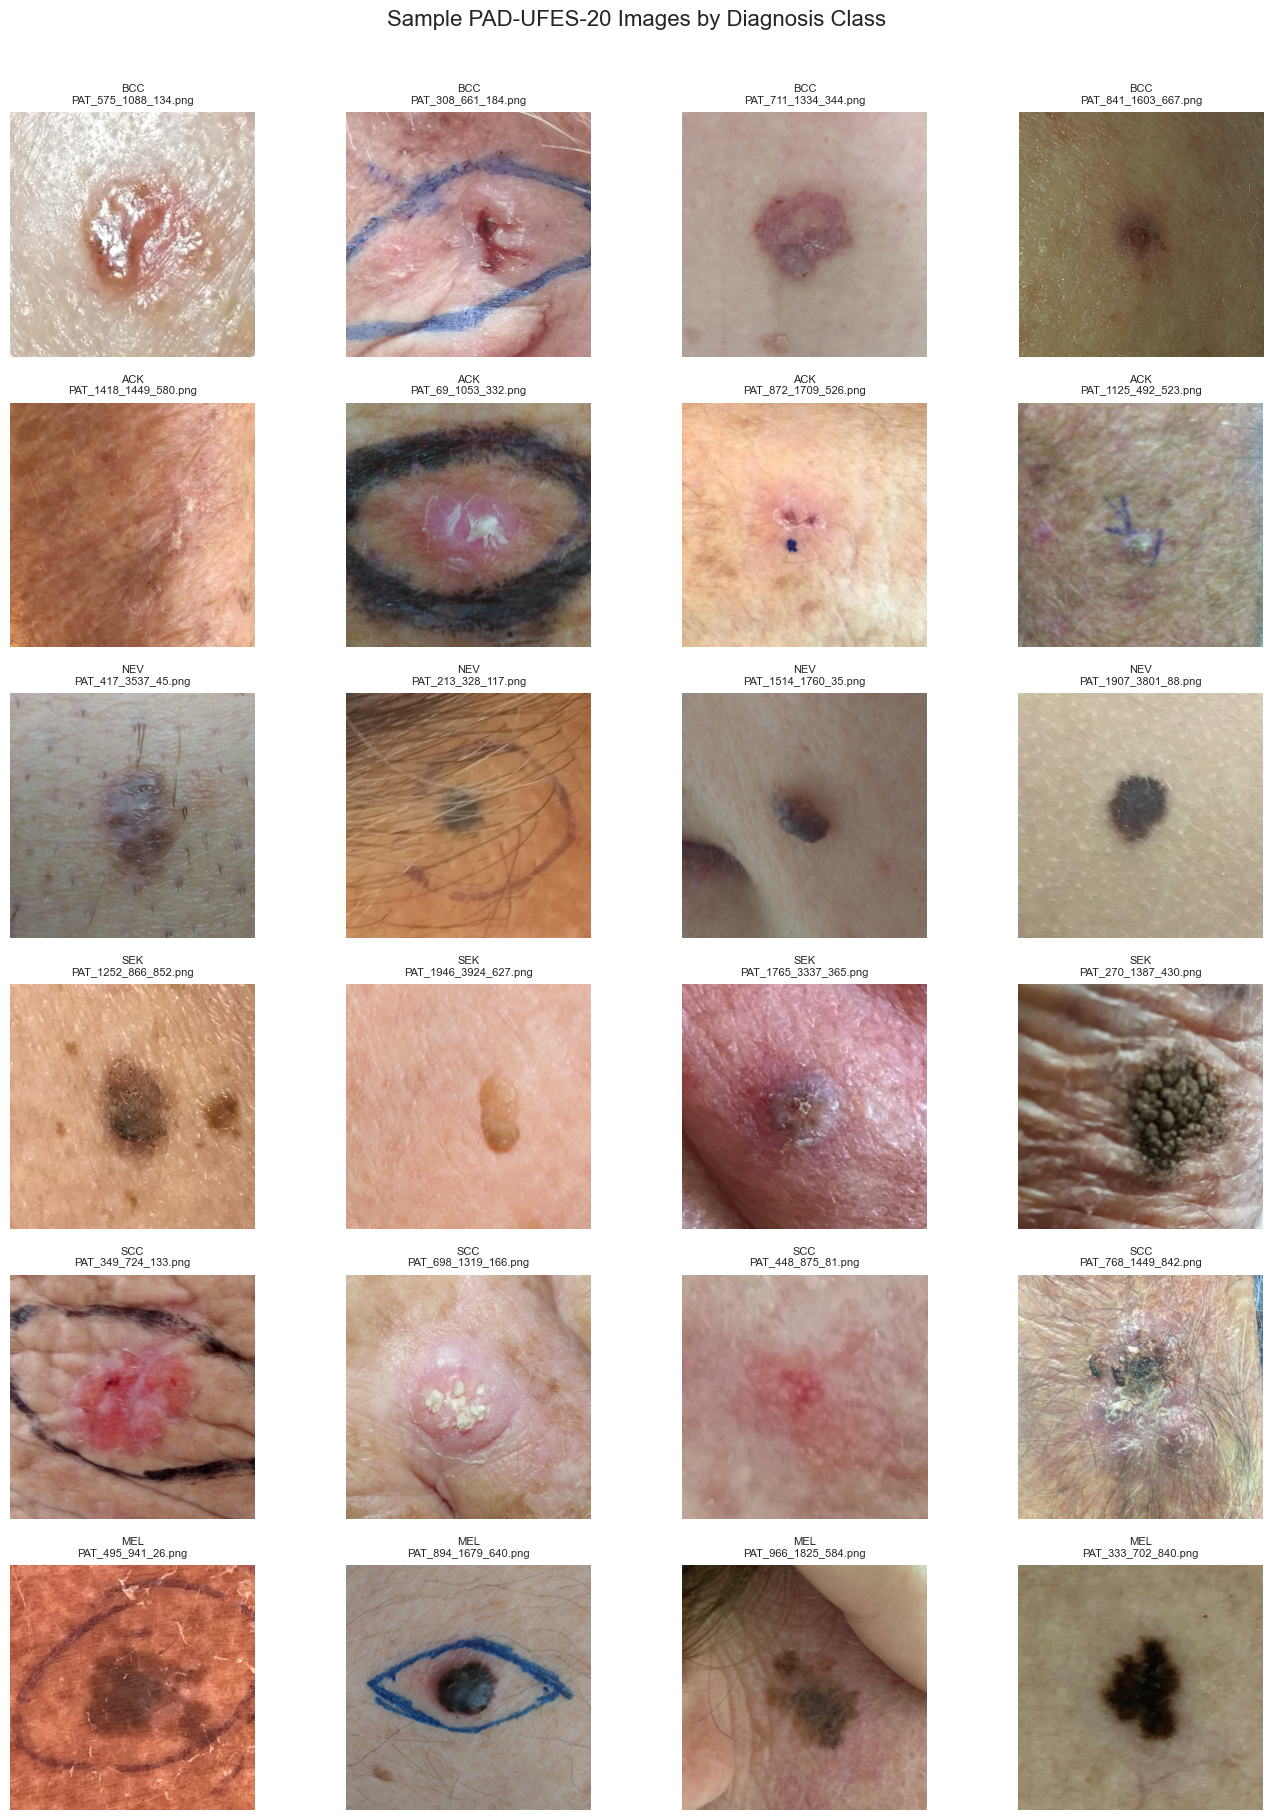

In [30]:
IMAGES_PER_CLASS = 4

fig, axes = plt.subplots(
    nrows=len(diagnosis_classes),
    ncols=IMAGES_PER_CLASS,
    figsize=(14, 3 * len(diagnosis_classes)),
    squeeze=False,
)

for row_idx, diagnosis in enumerate(diagnosis_classes):
    class_rows = features_df[features_df[LABEL_COL] == diagnosis]
    sampled = class_rows.sample(n=min(IMAGES_PER_CLASS, len(class_rows)), random_state=SEED)

    for col_idx in range(IMAGES_PER_CLASS):
        ax = axes[row_idx, col_idx]
        if col_idx < len(sampled):
            record = sampled.iloc[col_idx]
            show_image(ax, record["path"], f"{diagnosis}\n{record['filename']}")
        else:
            ax.axis("off")

plt.suptitle("Sample PAD-UFES-20 Images by Diagnosis Class", fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## 12. Image characteristics by diagnosis

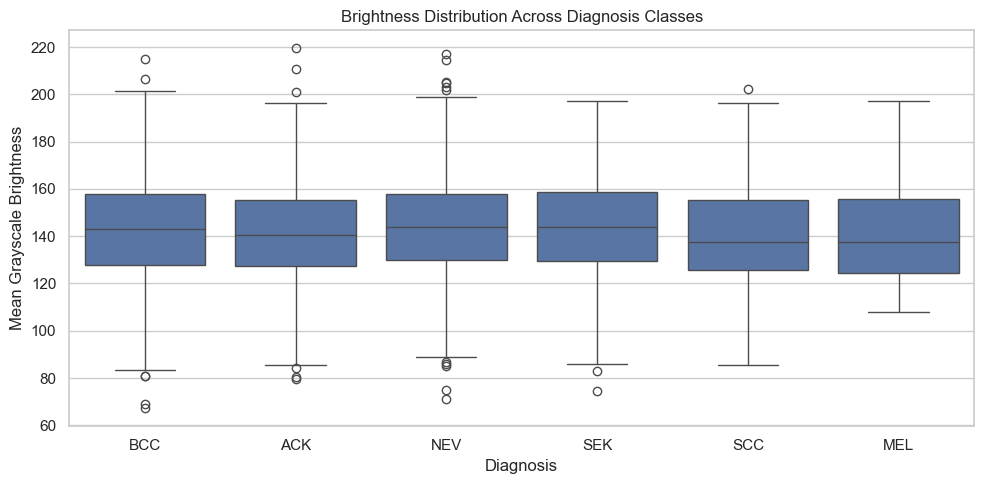

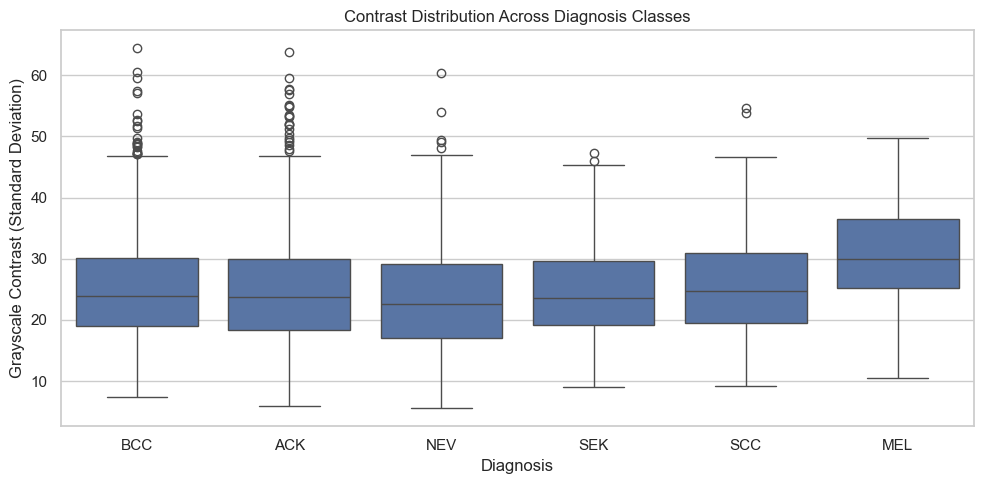

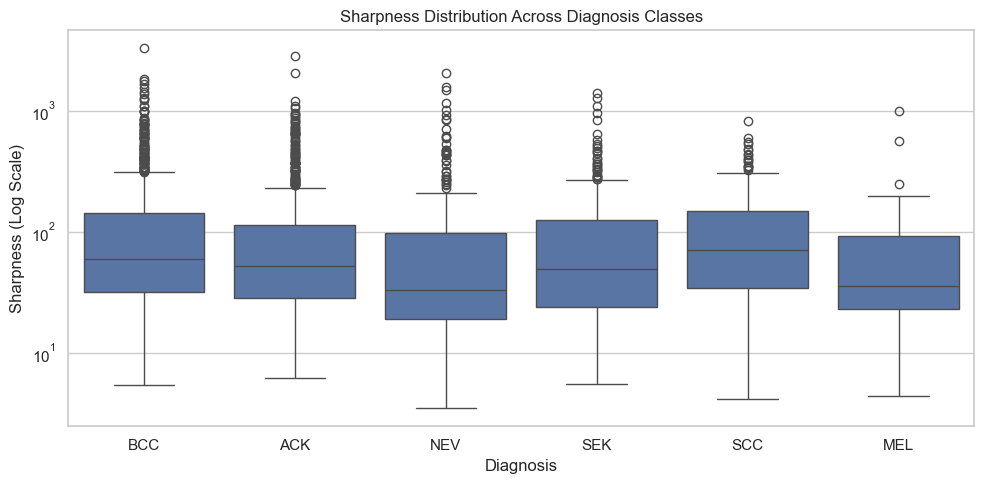

In [31]:
feature_plots = [
    ("brightness", "Mean Grayscale Brightness", False),
    ("contrast", "Grayscale Contrast (Standard Deviation)", False),
    ("sharpness", "Sharpness (Log Scale)", True),   # heavily right-skewed -> log scale
]

for feature, ylabel, log_scale in feature_plots:
    plt.figure(figsize=(10, 5))
    sns.boxplot(data=features_df, x=LABEL_COL, y=feature, order=diagnosis_classes)
    if log_scale:
        plt.yscale("log")
    plt.title(f"{feature.capitalize()} Distribution Across Diagnosis Classes")
    plt.xlabel("Diagnosis")
    plt.ylabel(ylabel)
    plt.tight_layout()
    plt.show()

In [32]:
class_feature_summary = (
    features_df
    .groupby(LABEL_COL)[["brightness", "contrast", "sharpness"]]
    .agg(["mean", "median", "std"])
    .round(2)
)
display(class_feature_summary)

brightness                contrast              sharpness         \
                 mean  median    std     mean median   std      mean median   
diagnostic                                                                    
ACK            141.07  140.70  21.19    25.20  23.73  9.47    119.50  51.75   
BCC            142.76  142.94  22.39    25.28  23.97  8.72    148.85  59.81   
MEL            140.64  137.67  20.98    30.15  29.96  8.85     86.54  35.47   
NEV            144.49  144.07  24.43    24.39  22.58  9.46    123.44  32.98   
SCC            141.18  137.60  22.96    25.83  24.69  8.95    119.51  70.13   
SEK            144.23  143.99  23.08    24.86  23.62  8.15    119.08  49.15   

                    
               std  
diagnostic          
ACK         208.13  
BCC         251.47  
MEL         158.02  
NEV         253.33  
SCC         129.00  
SEK         192.97

## 13. Duplicate images vs. diagnostic labels

For each group of byte-identical images, check whether the metadata assigns the same diagnosis to every copy.

In [33]:
duplicate_label_results = []

for group_number, filenames in enumerate(duplicate_groups.values(), start=1):
    records_in_group = metadata_df[metadata_df[ID_COL].isin(filenames)]
    diagnoses = sorted(records_in_group[LABEL_COL].dropna().unique())

    if len(diagnoses) == 1:
        label_status = "Same diagnosis"
    elif len(diagnoses) > 1:
        label_status = "Different diagnoses"
    else:
        label_status = "Missing diagnosis"

    duplicate_label_results.append({
        "duplicate_group": group_number,
        "filenames": ", ".join(filenames),
        "patient_ids": ", ".join(records_in_group[PATIENT_COL].astype(str).unique()),
        "lesion_ids": ", ".join(records_in_group[LESION_COL].astype(str).unique()),
        "diagnoses": ", ".join(diagnoses),
        "label_status": label_status,
    })

duplicate_label_df = pd.DataFrame(
    duplicate_label_results,
    columns=["duplicate_group", "filenames", "patient_ids", "lesion_ids", "diagnoses", "label_status"],
)

display(duplicate_label_df)

,duplicate_group,filenames,patient_ids,lesion_ids,diagnoses,label_status
0,1,"PAT_202_307_424.png, PAT_202_308_721.png",PAT_202,"307, 308","ACK, BCC",Different diagnoses
1,2,"PAT_302_650_477.png, PAT_302_651_529.png",PAT_302,"651, 650","BCC, SCC",Different diagnoses
2,3,"PAT_311_666_191.png, PAT_311_667_416.png",PAT_311,"666, 667","BCC, SCC",Different diagnoses
3,4,"PAT_38_1002_34.png, PAT_38_1003_68.png",PAT_38,"1002, 1003","ACK, BCC",Different diagnoses
4,5,"PAT_38_1002_668.png, PAT_38_1003_226.png",PAT_38,"1003, 1002","ACK, BCC",Different diagnoses
5,6,"PAT_419_2767_323.png, PAT_419_833_148.png",PAT_419,"2767, 833","ACK, SCC",Different diagnoses
6,7,"PAT_528_3072_615.png, PAT_528_993_589.png",PAT_528,"3072, 993",ACK,Same diagnosis
7,8,"PAT_56_86_479.png, PAT_56_88_274.png",PAT_56,"86, 88","BCC, SCC",Different diagnoses
8,9,"PAT_570_1084_637.png, PAT_570_1085_344.png",PAT_570,"1084, 1085","BCC, SCC",Different diagnoses
9,10,"PAT_570_1084_939.png, PAT_570_1085_429.png",PAT_570,"1085, 1084","BCC, SCC",Different diagnoses


In [34]:
print("Total duplicate groups:", len(duplicate_label_df))

print("\nDuplicate label consistency:")
print(duplicate_label_df["label_status"].value_counts())

print("\nDuplicate groups with different diagnoses:")
display(duplicate_label_df[duplicate_label_df["label_status"] == "Different diagnoses"])

Total duplicate groups: 15

Duplicate label consistency:
label_status
Different diagnoses    12
Same diagnosis          3
Name: count, dtype: int64

Duplicate groups with different diagnoses:


,duplicate_group,filenames,patient_ids,lesion_ids,diagnoses,label_status
0,1,"PAT_202_307_424.png, PAT_202_308_721.png",PAT_202,"307, 308","ACK, BCC",Different diagnoses
1,2,"PAT_302_650_477.png, PAT_302_651_529.png",PAT_302,"651, 650","BCC, SCC",Different diagnoses
2,3,"PAT_311_666_191.png, PAT_311_667_416.png",PAT_311,"666, 667","BCC, SCC",Different diagnoses
3,4,"PAT_38_1002_34.png, PAT_38_1003_68.png",PAT_38,"1002, 1003","ACK, BCC",Different diagnoses
4,5,"PAT_38_1002_668.png, PAT_38_1003_226.png",PAT_38,"1003, 1002","ACK, BCC",Different diagnoses
5,6,"PAT_419_2767_323.png, PAT_419_833_148.png",PAT_419,"2767, 833","ACK, SCC",Different diagnoses
7,8,"PAT_56_86_479.png, PAT_56_88_274.png",PAT_56,"86, 88","BCC, SCC",Different diagnoses
8,9,"PAT_570_1084_637.png, PAT_570_1085_344.png",PAT_570,"1084, 1085","BCC, SCC",Different diagnoses
9,10,"PAT_570_1084_939.png, PAT_570_1085_429.png",PAT_570,"1085, 1084","BCC, SCC",Different diagnoses
10,11,"PAT_691_1311_2.png, PAT_691_3994_671.png",PAT_691,"3994, 1311","ACK, BCC",Different diagnoses


---
## 14. Summary of findings


### 14.1 Additional EDA findings and interpretation

**1. Diagnosis-wise image visualisation**
- Four sample images were visualised for each of the six diagnostic classes.
- Images showed visual variations within and between classes.
- Some classes share similar visual characteristics, highlighting the challenge of image classification.

**2. Image characteristics by diagnosis**
- Brightness: mean values were similar across classes (140.64-144.49).
- Contrast: MEL had the highest mean (30.15), while NEV had the lowest (24.39).
- Sharpness: BCC had the highest mean (148.85), while MEL had the lowest (86.54).
- Large within-class variations were observed, so these metrics are not reliable diagnostic indicators.

**3. Image-to-label mapping verification**
- Total images: 2,298.
- Images without metadata records: 0.
- Metadata records without images: 0.
- Repeated filenames in metadata: 0.
- Missing diagnostic labels: 0.
- All images were successfully matched with their metadata records and labels.

**4. Duplicate image investigation**
- MD5 hashing identified 15 duplicate groups (15 additional copies).
- Unique image files: 2,283.
- 12 groups had conflicting diagnostic labels.
- 3 groups had matching diagnostic labels.
- Duplicate records shared patient IDs but had different lesion IDs.
- Identical images with conflicting labels may introduce ambiguity during CNN training.
- No records have been removed; further investigation is required before cleaning.

**5. Overall image EDA summary**
- All 2,298 images were successfully loaded.
- Images were predominantly square.
- Brightness, contrast and sharpness varied across images.
- The dataset showed substantial class imbalance, particularly for MEL (2.26%).
- All images were successfully matched to metadata and diagnostic labels.
- CNNs will automatically learn image features during training.

**6. Considerations for model development**
- Class imbalance: consider class weights or other balancing techniques.
- Evaluation: use macro-F1, per-class recall and confusion matrices alongside accuracy.
- Duplicates: finalise a suitable handling strategy before training.
- Data splitting: use patient-level splitting to prevent data leakage.
- Clustering: optional extension; encouraged but not compulsory.

### 14.2 EDA conclusion

- Exploratory Data Analysis was performed on the PAD-UFES-20 image dataset, consisting of 2,298 images across three image folders.
- All images were successfully loaded, with no unreadable files detected. Image dimensions varied considerably, although most images had approximately square aspect ratios.
- Brightness, contrast and sharpness measurements revealed variation in image characteristics.
- Exact duplicate detection identified 15 duplicate pairs, leaving 2,283 unique image files.
- The dataset contains six diagnostic classes with an imbalanced distribution. BCC and ACK represent the largest classes, accounting for 36.77% and 31.77% respectively, while MEL represents only 2.26%.
- The 2,298 image records correspond to 1,373 unique patients and 1,641 unique lesions, indicating that multiple images may belong to the same patient or lesion.
- These findings will inform the preprocessing, class imbalance handling and patient-level data splitting strategies used during model development.